## Income classification on census data

Binary classification to predict whether a person earns more than $50k/year from demographic and employment features.

Dataset: https://www.kaggle.com/datasets/amirhosseinmirzaie/americancitizenincome (to be downloaded and placed in `data/income.csv`)

The dataset has 25,000 rows, and a 75/25 class imbalance.

# 1. Import libraries

In [16]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split,RandomizedSearchCV,cross_validate,StratifiedKFold,ParameterGrid
from sklearn.ensemble import RandomForestClassifier,GradientBoostingClassifier
from sklearn.preprocessing import OneHotEncoder,FunctionTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.metrics import confusion_matrix,f1_score,ConfusionMatrixDisplay
from imblearn.over_sampling import SMOTE, RandomOverSampler
from imblearn.pipeline import Pipeline as IMBPipeline
from sklearn.decomposition import PCA
import itertools

SEED = 42
np.random.seed(SEED)

# 2. Dataset analysis

- The dataset used contains information about 25,000 American citizens. It has a binary classification objective of predicting whether a citizen's income will be above or below 50,000$.
- The dataset has mixed features and includes numerical and categorical data, both ordinal (eg. education) and nominal (eg. occupation).
- As shown below, there is no missing data. To simulate an incomplete dataset, some will be artificially added later.
- It does however have some unknown data, '?', which will be changed to NaN.
- The dataset is quite imbalanced, with a 75% to 25% split. Hence, resampling might be needed and high model performance may be harder to achieve.

In [17]:
df = pd.read_csv('data/income.csv')

print('Shape:',df.shape)
print('\nNull values:',df.isnull().sum().sum())
print('Target:',df[['income']].value_counts()/len(df))
df.head(3)

Shape: (25000, 15)

Null values: 0
Target: income
<=50K     0.7582
>50K      0.2418
Name: count, dtype: float64


,age,workclass,fnlwgt,education,education.num,marital.status,occupation,relationship,race,sex,capital.gain,capital.loss,hours.per.week,native.country,income
0,40,Self-emp-not-inc,223881,Prof-school,15,Married-civ-spouse,Prof-specialty,Husband,White,Male,99999,0,70,United-States,>50K
1,30,Private,149118,HS-grad,9,Divorced,Craft-repair,Not-in-family,White,Female,0,0,40,United-States,<=50K
2,46,Private,109209,Some-college,10,Married-civ-spouse,Adm-clerical,Husband,White,Male,0,0,40,United-States,>50K


# 3. Preprocessing

Missing Data:


As stated before, the unknown data will be replaced by NaN. Then, some of the data will be randomly deleted to simulate an incomplete dataset.

In [18]:
df = df.replace('?',np.nan)

def missing_col(column: pd.Series, percentage: float = 0.01) -> pd.Series:
    X = column.copy()
    X.iloc[np.random.choice(len(X), size=int(len(X)*percentage), replace = False)] = np.nan
    return X
def missing_row(df: pd.DataFrame, n: int = 1) -> pd.DataFrame:
    empty = pd.DataFrame(np.nan, index=range(len(df), len(df)+n), columns=df.columns)
    return pd.concat([df, empty])

df['age'] = missing_col(df['age'], 0.001)
df['marital.status'] = missing_col(df['marital.status'], 0.001)
df['hours.per.week'] = missing_col(df['hours.per.week'], 0.001)
df = missing_row(df, 10)
df.isnull().sum()

age                 35
workclass         1439
fnlwgt              10
education           10
education.num       10
marital.status      35
occupation        1444
relationship        10
race                10
sex                 10
capital.gain        10
capital.loss        10
hours.per.week      35
native.country     447
income              10
dtype: int64

The missing rows will be dropped as they have no use. The remaining missing data will instead be imputed when preprocessing the dataset later.

We also separate the dataset and the labels, fixing the format of the latter.

In [19]:
df = df.dropna(axis=0, how='all')

X, y = df.drop(['income'], axis=1), df[['income']]
y = np.array(pd.get_dummies(y, drop_first=True, dtype=int)).ravel()
y

array([1, 0, 1, ..., 1, 0, 0], shape=(25000,))

The preprocessing will be done through a column transformer, hence we need to decide how to handle each feature separately through a single transformer or a pipeline.

The chosen model won't require any feature scaling (as trees are scale-invariant), hence there won't be any need to use standardization or normalization in this step.

All nominal data will be one-hot encoded. While we won't have to deal with the curse of dimensionality, and can thus keep infrequent categories, some will still be merged together.

# Features:
- age: After artificially removing some data, we must impute to bring it back. We use median to avoid fractional age.
- workclass: Requires mode imputing due to unknown data. To reduce the number of dimensions, we combine related categories.

In [20]:
age = SimpleImputer(strategy='median')

wc_dict = {'Self-emp-not-inc':'self-emp','Self-emp-inc':'self-emp',
    'Local-gov':'gov','State-gov':'gov','Federal-gov':'gov'}
workclass = Pipeline([
    ("merge",FunctionTransformer(lambda DF: DF.map(lambda x: wc_dict[x] if x in wc_dict else x))),
    ("impute",SimpleImputer(strategy='most_frequent')),
    ("onehot",OneHotEncoder(drop='first',handle_unknown='ignore',min_frequency=0.01))
])

X[['workclass']].value_counts()

workclass       
Private             17471
Self-emp-not-inc     1935
Local-gov            1553
State-gov            1004
Self-emp-inc          851
Federal-gov           740
Without-pay            12
Never-worked            5
Name: count, dtype: int64

- fnlwgt: A "representative sample" with no value for the model, which will be dropped.
- education: Categorical feature that has already been converted into an ordinal. It can thus be dropped safely, keeping "education.num".

In [21]:
X = X.drop(['fnlwgt','education'],axis=1)
df[['education','education.num']].value_counts().count() - df[['education']].nunique() # Education and education.num are the same.

education    0
dtype: int64

- marital.status: Due to missing data, it requires mode imputing. We will also combine some of its categories to reduce dimensions.
- occupation: Requires mode imputing.
- relationship, race, sex: One hot encoding with a small min-frequency.
- native country: Given the large amount of nominal categories, we simply distinguish between US and non-US.
- hours per week: Just like age, we impute using the median.

In [22]:
onehot = OneHotEncoder(drop='first',handle_unknown='ignore',min_frequency=0.015)

occupation = Pipeline([
    ("impute",SimpleImputer(strategy='most_frequent')),
    ("onehot",OneHotEncoder(drop='first',handle_unknown='ignore',min_frequency=0.015))
])

ms_dict = {'Married-AF-spouse':'Married','Married-spouse-absent':'Married', 'Married-civ-spouse':'Married'}
ms = Pipeline([
    ("merge",FunctionTransformer(lambda X: X.map(lambda x: ms_dict[x] if x in ms_dict else x))),
    ("impute",SimpleImputer(strategy='most_frequent')),
    ("onehot",OneHotEncoder(drop='first',handle_unknown='ignore'))
])

country = Pipeline([
    ("merge",FunctionTransformer(lambda X: X.map(lambda x: "US" if x == 'United-States' else 'Other'))),
    ("onehot",OneHotEncoder(drop='first',handle_unknown='ignore'))
])

hpw = SimpleImputer(strategy='most_frequent')

print(X[['marital.status']].value_counts())
print(f"\nUS natives: {int(X[['native.country']].value_counts().iloc[0])} | Unique countries: {int(X[['native.country']].nunique().iloc[0])}")

marital.status       
Married-civ-spouse       11501
Never-married             8198
Divorced                  3388
Separated                  792
Widowed                    766
Married-spouse-absent      312
Married-AF-spouse           18
Name: count, dtype: int64

US natives: 22415 | Unique countries: 40


We can now construct the column transformer, and divide the dataset into training and testing sets. We will stratify so the proportion of classes remains the same.

Given the preprocessing step involves imputing, which can leak data, we must make sure to fit it only on the training set going forward.

In [23]:
preprocess = ColumnTransformer([
    ('age', age, ['age']),
    ('workclass', workclass, ['workclass']),
    ('marital', ms, ['marital.status']),
    ('occupation', occupation, ['occupation']),
    ('onehot', onehot, ['relationship','race','sex']),
    ('native country', country, ['native.country']),
    ('hours per week', hpw, ['hours.per.week'])
], remainder='passthrough',sparse_threshold=0)

X_train, X_test, y_train, y_test = train_test_split(X, y, stratify=y, random_state=SEED)

# 4. Model selection

We can first test whether the preprocessing was successful and try fitting a simple model with no further steps.

We fit two reference models: a majority-class dummy and a decision tree. These are the baselines the final model has to beat.

In [24]:
preprocess.fit(X_train,y_train)
X_train_p, X_test_p = preprocess.transform(X_train), preprocess.transform(X_test)

from sklearn.dummy import DummyClassifier
from sklearn.tree import DecisionTreeClassifier
for name, baseline in [('Majority class', DummyClassifier(strategy='most_frequent')),
                    ('Decision tree', DecisionTreeClassifier(random_state=SEED))]:
    baseline.fit(X_train_p, y_train)
    pred = baseline.predict(X_test_p)
    print(f"{name}: Accuracy={baseline.score(X_test_p, y_test):.3f}, F1={f1_score(y_test, pred):.3f}")

Majority class: Accuracy=0.758, F1=0.000
Decision tree: Accuracy=0.815, F1=0.610


For the model itself, we will use a pipeline that includes preprocessing, resampling and a classifier:

- Preprocessing will use the column transformer.
- Resampling will use SMOTE, which will create synthetic new samples. While the model is scale-invariant, SMOTE is based on KNN (which uses Euclidean distance), so we must do feature scaling anyway. We use Robust Scaling as the dataset contains many outliers, particularly in "capital.gain" and "capital.loss".
- For the classifier, we use a random forest which works well with mixed data.

In [25]:
from sklearn.preprocessing import RobustScaler,StandardScaler
model = IMBPipeline([
    ('preprocess', preprocess),
    ('scale', RobustScaler()),
    ('resample', SMOTE(random_state=SEED)),
    ('dim_reduction', None),
    ('classifier', RandomForestClassifier(random_state=SEED))
])
model.fit(X_train,y_train)
print("Accuracy:", model.score(X_test,y_test))
print("F1 score:",f1_score(y_test,model.predict(X_test)))
print("Confusion matrix:\n",confusion_matrix(y_test,model.predict(X_test)))

Accuracy: 0.84192
F1 score: 0.6673400673400673
Confusion matrix:
 [[4271  468]
 [ 520  991]]


The result can still be improved, for example by switching the random forest classifier with a Gradient Boost.

To find the best model, we will be using a randomized grid search to hopefully improve the f1 score.

Given the complexity of the dataset, other types of classifiers like SVC or K-NN will struggle, so they won't be included.

In [26]:
resample = [
    {'resample': [None]},
    {'resample': [SMOTE(random_state=SEED)],
     'resample__k_neighbors': [1,3,5,7]},
    {'resample': [RandomOverSampler(random_state=SEED)]}
]
scale = [
    {'scale': [None]},
    {'scale': [StandardScaler()]},
    {'scale': [RobustScaler()]}
]
dim_reduction = [
    {'dim_reduction': [None]},
    {'dim_reduction': [PCA()],
    'dim_reduction__n_components': [20,25,30]}
]
classifier = [
    {'classifier': [RandomForestClassifier(random_state=SEED)],
     'classifier__n_estimators': [50,100,200,300]},
    {'classifier': [GradientBoostingClassifier(random_state=SEED)],
     'classifier__learning_rate': [0.01, 0.05, 0.1, 0.2],
     'classifier__n_estimators': [10,50,100,200]}
]

search = []
for option in itertools.product(scale, resample, dim_reduction, classifier):
    params = []
    for element in option:
        params.extend(list(element.items()))
    search.append(dict(params))

SAMPLED = 10
rscv = RandomizedSearchCV(model, param_distributions=search, n_jobs=-1, scoring='f1', n_iter=SAMPLED, random_state=SEED)

print(f"options: {len(search)} | configurations: {len(ParameterGrid(search))} | sampled: {SAMPLED}")

rscv.fit(X_train, y_train)

options: 36 | configurations: 1440 | sampled: 10


,"estimator estimator: estimator objectAn object of that type is instantiated for each grid point.This is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Pipeline(step...m_state=42))])
,"param_distributions param_distributions: dict or list of dictsDictionary with parameters names (`str`) as keys and distributionsor lists of parameters to try. Distributions must provide a ``rvs``method for sampling (such as those from scipy.stats.distributions).If a list is given, it is sampled uniformly.If a list of dicts is given, first a dict is sampled uniformly, andthen a parameter is sampled using that dict as above.","[{'classifier': [RandomForestC...ndom_state=42)], 'classifier__n_estimators': [50, 100, ...], 'dim_reduction': [None], 'resample': [None], ...}, {'classifier': [GradientBoost...ndom_state=42)], 'classifier__learning_rate': [0.01, 0.05, ...], 'classifier__n_estimators': [10, 50, ...], 'dim_reduction': [None], ...}, ...]"
,"n_iter n_iter: int, default=10Number of parameter settings that are sampled. n_iter tradesoff runtime vs quality of the solution.",10
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion ` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.If None, the estimator's score method is used.",'f1'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary `for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given the ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``RandomizedSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`this example`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",True
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- An iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. The

Best config: {'scale': None, 'resample': RandomOverSampler(random_state=42), 'dim_reduction__n_components': 25, 'dim_reduction': PCA(), 'classifier__n_estimators': 200, 'classifier__learning_rate': 0.1, 'classifier': GradientBoostingClassifier(random_state=42)}
Best inner-CV F1: 0.705

TEST SET:
Accuracy: 0.83216
Precision: 0.610738255033557
Recall: 0.8431502316346791
F1 score: 0.7083680845148735


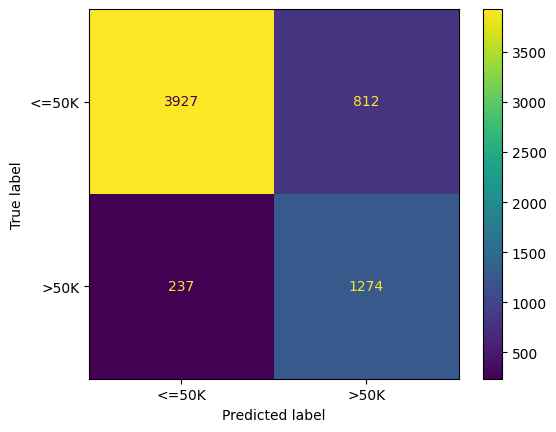

In [27]:
from sklearn import metrics
y_pred = rscv.predict(X_test)

print("Best config:", rscv.best_params_)
print("Best inner-CV F1:", round(rscv.best_score_, 3))
print("\nTEST SET:")
print("Accuracy:", metrics.accuracy_score(y_test, y_pred))   # (TP+TN) / (all)
print("Precision:", metrics.precision_score(y_test, y_pred)) # TP / (TP+FP)
print("Recall:", metrics.recall_score(y_test, y_pred))       # TP / (TP+FN)
print("F1 score:", f1_score(y_test, y_pred))                 # 2*P*R / (P+R)

ConfusionMatrixDisplay.from_predictions(y_test, y_pred, display_labels=['<=50K', '>50K'])
plt.show()

The tuned model is compared against the baselines: the majority-class dummy (accuracy around 75%, F1 of 0) and the decision tree. Accuracy is misleading with a 75/25 split, so we report F1, precision and recall alongside it.

Next, we perform nested cross-validation to estimate how well tuning generalizes.

In [28]:
outer_cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
nested = cross_validate(rscv, X_train, y_train, scoring='f1', cv=outer_cv, n_jobs=-1)

print("Nested CV F1 per fold:", nested['test_score'].round(3))
print(f"Mean CV F1: {nested['test_score'].mean():.3f} (+/- {nested['test_score'].std():.3f})")

Nested CV F1 per fold: [0.7   0.695 0.696 0.722 0.711]
Mean CV F1: 0.705 (+/- 0.010)


## Conclusion
- The chosen dataset was imbalanced and quite complex, requiring multiple steps during preprocessing. In fact, further processing of the nominal categories, such as merging semantically related ones, might have yielded better results.

- After artificially introducing and then dealing with missing data by imputing, the dataset was preprocessed by dealing with its categorical features and combining some infrequent or related categories. No feature scaling was applied during preprocessing to allow for greater search options later.

- As preprocessing occurs inside the pipeline, it is fit only on training data in all CV folds.

- Model selection used randomized search over scaling, resampling (none, SMOTE or random oversampling), optional PCA, and random forest vs gradient boosting, scored with F1. Generalization was estimated with nested cross-validation and the tuned model was evaluated once on the test set (held-out).

- The selected configuration and the final metrics are printed above. We notice that the tuned model has lower accuracy than the untuned forest. This is to be expected, as the search optimizes for F1, accepting more false positives.